In [44]:
# %pip install pillow pillow-heif

In [7]:
# %pip install tensorflow
%pip install opencv-contrib-python

  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl (53.8 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np 
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import os
# import shutil
# from PIL import Image
# from pillow_heif import register_heif_opener
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

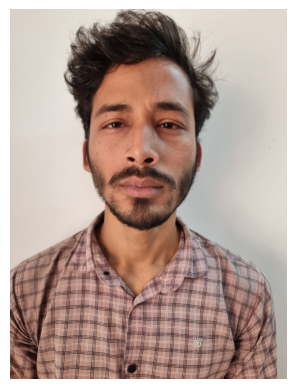

In [ ]:
# img_path = './emotions_dataset_final/train/Anger/20251012_111334.jpg'
# img = plt.imread(img_path)
# plt.imshow(img)
# plt.axis('off')
# plt.show()

Converting heif data into jpg formate as heif can cause trouble while working in cnn 

In [47]:
# register_heif_opener()

# source = './emotion_dataset'
# destination = './processed_dataset'

In [48]:
# for emotion in os.listdir(source):
#     src_folder = os.path.join(source,emotion)
#     if not os.path.isdir(src_folder):
#         continue
#     dst_folder = os.path.join(destination,emotion)
#     os.makedirs(dst_folder,exist_ok=True)
#     for filename in os.listdir(src_folder):
#         src_path = os.path.join(src_folder,filename)
#         name,ext = os.path.splitext(filename)
#         ext = ext.lower()
#         if ext in ['.heif','.heic']:
#             img = Image.open(src_path)
#             img = img.convert('RGB')

#             output_path = os.path.join(dst_folder,name+'.jpg')
#             print('converted:',filename)
#             img.save(output_path,'JPEG',quality = 95)
#         elif ext in ['.jpg' , '.jpeg','.png']:
#             shutil.copy2(
#                 src_path,os.path.join(dst_folder,filename)
#             )
# print('Conversion completed!')

In [2]:
train_gen = ImageDataGenerator(
            shear_range = 0.2,
            horizontal_flip = True,
            zoom_range = 0.15,
            rescale = 1/255
)

test_gen = ImageDataGenerator(
            rescale = 1/255
)

In [50]:
training_set = train_gen.flow_from_directory(
                './emotions_dataset_final/train',
                target_size = (128,128),
                batch_size = 32,
                class_mode = 'sparse'
)
testing_set = test_gen.flow_from_directory(
    './emotions_dataset_final/test',
    target_size = (128,128),
    batch_size = 32,
    class_mode = 'sparse'
)

Found 9619 images belonging to 5 classes.
Found 2404 images belonging to 5 classes.


In [51]:
training_set.image_shape

(128, 128, 3)

In [52]:
training_set.class_indices

{'Anger': 0, 'Fear': 1, 'Happy': 2, 'Neutral': 3, 'Sad': 4}

In [53]:
training_set.classes

array([0, 0, 0, ..., 4, 4, 4], shape=(9619,), dtype=int32)

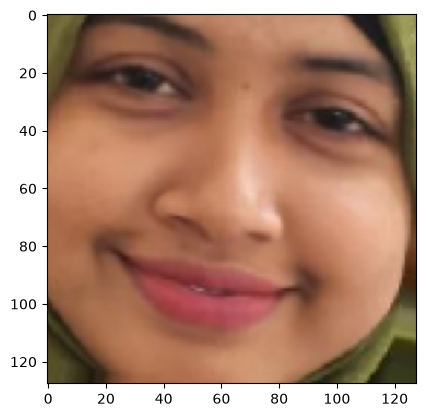

In [54]:
i,j = training_set[0]
im = i[0].reshape(128,128,3)
plt.imshow(im)

In [55]:
i.shape

(32, 128, 128, 3)

In [56]:
type(i)

numpy.ndarray

## Building the CNN

In [57]:
cnn = tf.keras.models.Sequential([tf.keras.layers.Input(shape=(128,128,3))])

In [58]:
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size = 3 ,padding='same', activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [59]:
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [60]:
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [61]:
cnn.add(tf.keras.layers.Flatten())

In [62]:
cnn.compile(optimizer='adam' , loss = 'sparse_categorical_crossentropy',metrics=['accuracy'])

In [63]:
cnn.add(tf.keras.layers.Dense(units=128,activation='relu'))
cnn.add(tf.keras.layers.Dense(units=5,activation='softmax'))
        

In [64]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

history = cnn.fit(x = training_set, validation_data=testing_set , epochs=100,callbacks=[early_stop])

Epoch 1/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 248s 821ms/step - accuracy: 0.4450 - loss: 1.2873 - val_accuracy: 0.6364 - val_loss: 0.9268
Epoch 2/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 152s 454ms/step - accuracy: 0.7196 - loss: 0.7241 - val_accuracy: 0.7230 - val_loss: 0.7036
Epoch 3/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 206s 685ms/step - accuracy: 0.8187 - loss: 0.4722 - val_accuracy: 0.8390 - val_loss: 0.4325
Epoch 4/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 203s 673ms/step - accuracy: 0.8638 - loss: 0.3602 - val_accuracy: 0.8760 - val_loss: 0.3395
Epoch 5/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 201s 667ms/step - accuracy: 0.8940 - loss: 0.2910 - val_accuracy: 0.8760 - val_loss: 0.3355
Epoch 6/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 207s 689ms/step - accuracy: 0.9108 - loss: 0.2422 - val_accuracy: 0.8960 - val_loss: 0.2963
Epoch 7/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 209s 695ms/step - accuracy: 0.9219 - loss: 0.2114 - val_accuracy: 0.9189 - val_loss: 0.2235
Epoch 8/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 198s 657ms/step - accuracy: 

In [69]:
loss , acc = cnn.evaluate(testing_set)
print(f'loss : {loss} and acc :{acc}')

76/76 ━━━━━━━━━━━━━━━━━━━━ 15s 196ms/step - accuracy: 0.9326 - loss: 0.1988
loss : 0.19883204996585846 and acc :0.9326122999191284


In [70]:
cnn.save('Emotion_detection_model.keras')

In [120]:
emotion_label = ['Anger' , 'Fear' , 'Happy' , 'Neutral' , 'Sad']

for emotion in emotion_label:
    path = os.path.join('./emotions_dataset_final/test',emotion)
    files = os.listdir(path)
    print(len(files))

250
491
533
562
568


'aug_0_9806.jpg'

In [3]:
emotion_label = ['Anger' , 'Fear' , 'Happy' , 'Neutral' , 'Sad']
def get_file():
    num = np.random.randint(0,5)
    emotion = emotion_label[num]
    dict_emotion = {'Anger':250 , 'Fear' : 491 , 'Happy' : 533, 'Neutral' : 562, 'Sad' : 568}
    files = os.listdir(f'./emotions_dataset_final/test/{emotion}')
    num2 = np.random.randint(dict_emotion[emotion])
    filename = files[num2]
    img_path = f'./emotions_dataset_final/test/{emotion}/{filename}'
    img = plt.imread(img_path)
    img = cv2.resize(img,(128,128))
    return img

In [ ]:
var = get_file()
plt.imshow(var)
var = var.reshape(1,128,128,3)
pred = np.argmax(cnn.predict(var),axis=1)
plt.title(emotion_label[pred[0]])
plt.axis('off')
plt.show()
# pred[0]

In [78]:
cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,864,977 (49.08 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,576,652 (32.72 MB)

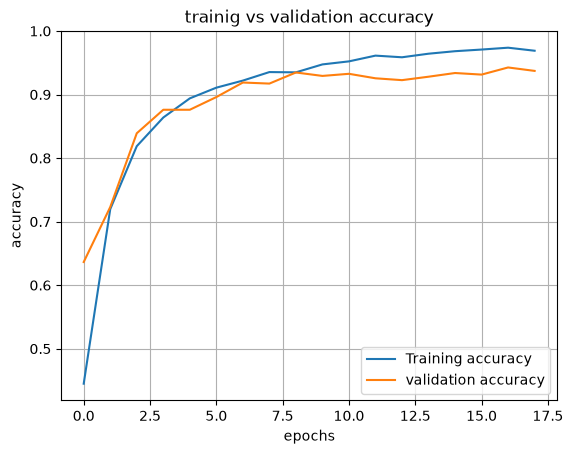

In [169]:
plt.plot(history.history['accuracy'] , label = 'Training accuracy')
plt.plot(history.history['val_accuracy'] , label = 'validation accuracy')

plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.title('trainig vs validation accuracy')
plt.legend()
plt.grid(True)
plt.show()

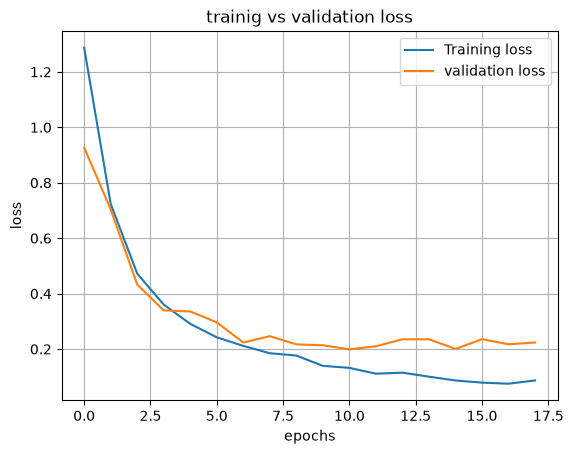

In [170]:
plt.plot(history.history['loss'] , label = 'Training loss')
plt.plot(history.history['val_loss'] , label = 'validation loss')

plt.xlabel('epochs')
plt.ylabel('loss')
plt.title('trainig vs validation loss')
plt.legend()
plt.grid(True)
plt.show()

In [1]:
cnn_model = tf.keras.models.load_model(
    'Emotion_detection_model.keras'
)
print('model loaded successfully')

NameError: name 'tf' is not defined